# 5. In-silico Method Comparison
- Plots the cached in-silico benchmark (`5_MethodComparison/cache/plot_data.pkl`, from `notebookscripts/MethodComparison/plot_pr.py`) across arms and log2FC levels.

In [1]:
%load_ext autoreload
%autoreload 2

import os
import pickle
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

os.environ["NM_PIPELINE"] = "p3"
sys.path.insert(0, str(Path.cwd().parents[1]))
from viz_style import apply_style

import MixedEffectsModeling.config as config
from MixedEffectsModeling.notebookscripts.MethodComparison.common import ARMS, COLORS, LABELS, Q_LEVELS, Q_MARKERS, SPLIT_TITLE, STYLES

apply_style()

CACHE = config.METHOD_COMP_CACHE_DIR
FIGDIR = config.METHOD_COMP_FIG_DIR
FIGDIR.mkdir(parents=True, exist_ok=True)

LOG2FCS_SHOWN = [2.0, 3.0, 4.0, 5.0]


In [2]:
D = pickle.loads((CACHE / "plot_data.pkl").read_bytes())
Q_GRID, RECALL_GRID = D["q_grid"], D["recall_grid"]
print(sorted({f for f, _ in D["cv"]["curves"]}), "log2FC levels cached")

[2.0, 3.0, 4.0, 5.0] log2FC levels cached


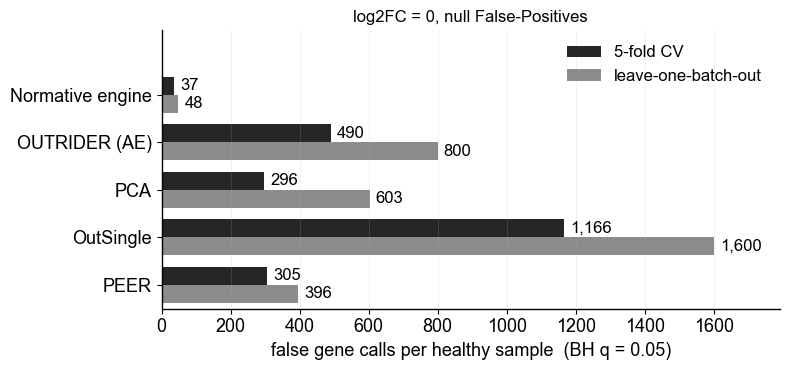

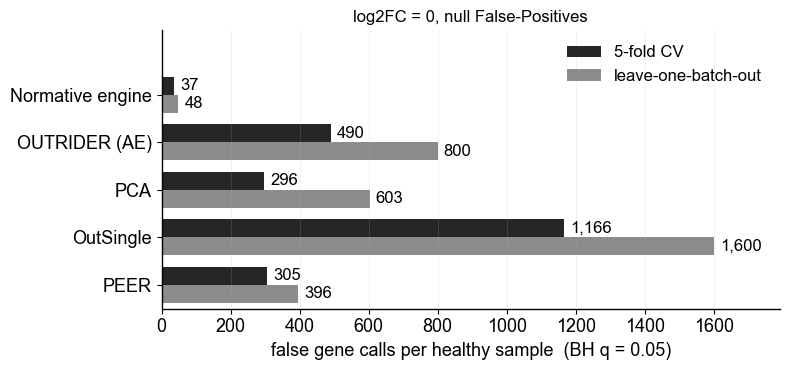

In [3]:
def null_falsecalls(q=0.05, save=True):
    n_genes = len((CACHE / "eval_universe_nm.txt").read_text().split())
    lg = np.log10(np.maximum(Q_GRID, 1e-12))
    rate = lambda sp, a: np.interp(np.log10(q), lg, D["null"][(sp, a)])
    fig, ax = plt.subplots(figsize=(8.0, 3.8))
    h = 0.38
    xmax = max(rate(sp, a) for sp in ("cv", "lobo") for a in ARMS) * n_genes * 1.12
    for k, split in enumerate(("cv", "lobo")):
        y = np.arange(len(ARMS)) + (k - 0.5) * h
        val = np.array([rate(split, a) * n_genes for a in ARMS])
        ax.barh(y, val, height=h, color="0.15" if split == "cv" else "0.55",
                edgecolor="none", label=SPLIT_TITLE[split])
        for yi, v in zip(y, val):
            ax.text(v + xmax * 0.01, yi, f"{v:,.0f}", va="center", fontsize=12)
    ax.set_xlim(0, xmax); ax.set_ylim(len(ARMS) - 0.5, -1.35)
    ax.set_yticks(range(len(ARMS))); ax.set_yticklabels([LABELS[a] for a in ARMS])
    ax.set_xlabel(f"false gene calls per healthy sample  (BH q = {q:g})")
    ax.grid(axis="x", alpha=0.25, lw=0.5)
    ax.legend(frameon=False, fontsize=12, loc="upper right", ncol=1, bbox_to_anchor=(0.995, 1.0))
    ax.set_title("log2FC = 0, null False-Positives", fontsize=12)
    fig.tight_layout()
    if save:
        fig.savefig(FIGDIR / "null_falsecalls.png", dpi=300, bbox_inches="tight")
    return fig

null_falsecalls()

In [4]:
# Inflation factor: observed / nominal. 1.0 = perfectly calibrated, >1 = anti-conservative.
import pandas as pd

alphas = [1e-4, 1e-3, 1e-2, 0.05]
idx = np.searchsorted(Q_GRID, alphas)
rows = {(SPLIT_TITLE[s], LABELS[a]): D["pcal"][(s, a)][idx] / np.array(alphas)
        for s in ("cv", "lobo") for a in ARMS}
pd.DataFrame(rows, index=[f"alpha={a:g}" for a in alphas]).T.round(2)

alpha=0.0001  alpha=0.001  alpha=0.01  \
5-fold CV           Normative engine         14.05         3.90        1.64   
                    OUTRIDER (AE)           220.65        30.11        4.86   
                    PCA                     113.19        17.45        3.19   
                    OutSingle               419.75        61.82       10.40   
                    PEER                    102.18        17.19        3.53   
leave-one-batch-out Normative engine         17.68         4.66        1.80   
                    OUTRIDER (AE)           347.05        47.41        7.57   
                    PCA                     228.93        34.04        5.82   
                    OutSingle               562.03        82.83       13.71   
                    PEER                    129.90        22.09        4.53   

                                      alpha=0.05  
5-fold CV           Normative engine        1.19  
                    OUTRIDER (AE)           1.67  
                    PCA                     1.19  
                    OutSingle               3.45  
                    PEER                    1.45  
leave-one-batch-out Normative engine        1.25  
                    OUTRIDER (AE)           2.51  
                    PCA                     1.99  
                    OutSingle               4.39  
                    PEER                    1.84

In [5]:
def pr_grid(log2fcs=LOG2FCS_SHOWN, splits=("cv", "lobo"), arms=ARMS, band=True, save=True):
    """Line = per-fold median, ribbon = fold IQR, markers = the reported BH levels placed at
    the median recall reached there and read off the curve, so they sit ON the line."""
    fig, axes = plt.subplots(len(splits), len(log2fcs),
                             figsize=(2.7 * len(log2fcs), 2.4 * len(splits)),
                             sharex=True, sharey=True, squeeze=False)
    for i, split in enumerate(splits):
        for j, f in enumerate(log2fcs):
            ax = axes[i, j]
            bands, ops = D[split]["bands"], D[split]["ops"]
            for arm in arms:
                lo, med, hi = bands[(f, arm)]
                if band:
                    ax.fill_between(RECALL_GRID, lo, hi, color=COLORS[arm], alpha=0.15, lw=0)
                ax.plot(RECALL_GRID, med, color=COLORS[arm], ls=STYLES[arm],
                        lw=2.0 if arm == "engine" else 1.4,
                        label=LABELS[arm] if (i, j) == (0, 0) else None,
                        zorder=4 if arm == "engine" else 3)
                for q in Q_LEVELS:
                    r = ops[("med", q, f, arm)][0]
                    ax.plot(r, np.interp(r, RECALL_GRID, med), marker=Q_MARKERS[q], ms=6,
                            color=COLORS[arm], mec="white", mew=0.6, ls="none", zorder=5)
            ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
            ax.grid(alpha=0.2, lw=0.5)
            if i == 0:
                ax.set_title(f"log2FC = {f:g}")
            if j == len(log2fcs) - 1:
                ax.text(1.06, 0.5, SPLIT_TITLE[split], rotation=270, va="center",
                        ha="left", fontsize=12, transform=ax.transAxes,
                        bbox=dict(facecolor="0.92", edgecolor="none", pad=3))
            if j == 0:
                ax.set_ylabel("Precision")
            if i == len(splits) - 1:
                ax.set_xlabel("Recall")
    h, l = axes[0, 0].get_legend_handles_labels()
    leg = fig.legend(h, l, loc="upper left", bbox_to_anchor=(1.02, 0.95), frameon=False,
                     fontsize=12, title="Method")
    leg.get_title().set_fontsize(12)
    qh = [plt.Line2D([], [], marker=m, ls="none", color="0.3", ms=4, mec="white", mew=0.6)
          for m in Q_MARKERS.values()]
    leg2 = fig.legend(qh, [str(q) for q in Q_MARKERS], loc="upper left",
                      bbox_to_anchor=(1.02, 0.55), frameon=False, fontsize=12, title="BH q")
    leg2.get_title().set_fontsize(12)
    fig.tight_layout()
    if save:
        fig.savefig(FIGDIR / "pr_grid.png", dpi=300, bbox_inches="tight")
    return fig

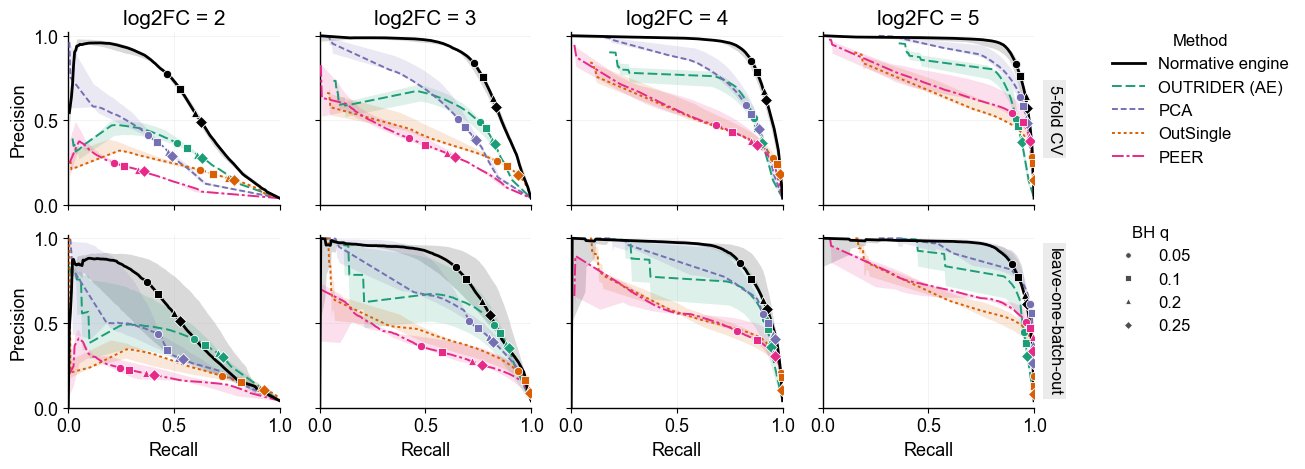

In [6]:
pr_grid();

In [7]:
def persample_confusion(q=0.05):
    c = pd.read_csv(CACHE / "sweep_nm_counts.csv")
    c = c[c["q"] == q].groupby(["split", "arm", "log2fc"])[["tp", "fp", "fn", "tn", "n_samples"]].sum()
    out = c[["tp", "fp", "fn", "tn"]].div(c["n_samples"], axis=0)
    out.columns = ["TP", "FP", "FN", "TN"]
    return out


CONF = persample_confusion()
CONF.unstack("log2fc").round(1)

TP                                         FP          \
log2fc              0.0    1.0    2.0    3.0    4.0    5.0     0.0     1.0   
split arm                                                                    
cv    autoencoder  20.1   81.8  260.4  380.6  435.1  459.9   469.8   465.1   
      engine        1.6   31.7  230.7  363.1  427.2  460.2    35.2    47.1   
      outsingle    47.8  140.2  309.3  416.8  477.0  495.4  1118.4  1124.8   
      pca          12.2   44.8  192.5  324.5  412.0  466.5   284.2   272.3   
      peer         12.4   28.6  106.3  216.8  338.4  448.2   292.6   289.7   
lobo  autoencoder  32.9  110.7  288.0  397.8  444.9  465.5   767.3   769.8   
      engine        1.9   28.8  184.9  322.6  404.2  448.7    46.1    58.3   
      outsingle    65.4  166.9  337.5  436.7  483.9  495.9  1534.3  1535.5   
      pca          24.9   76.7  234.9  360.3  439.1  480.0   577.8   555.0   
      peer         16.1   32.8  120.2  240.3  367.7  464.0   379.6   378.1   

                                   ...     FN                           TN  \
log2fc                2.0     3.0  ...    2.0    3.0    4.0   5.0      0.0   
split arm                          ...                                       
cv    autoencoder   459.0   447.6  ...  239.6  119.4   64.9  40.1  11177.2   
      engine         67.0    77.7  ...  269.3  136.9   72.8  39.8  11611.8   
      outsingle    1163.3  1187.6  ...  190.7   83.2   23.0   4.6  10528.6   
      pca           283.4   286.2  ...  307.5  175.5   88.0  33.5  11362.8   
      peer          307.3   326.4  ...  393.7  283.2  161.6  51.8  11354.4   
lobo  autoencoder   764.7   750.9  ...  212.0  102.2   55.1  34.5  10879.7   
      engine         78.0    87.1  ...  315.1  177.4   95.8  51.3  11600.9   
      outsingle    1578.0  1603.5  ...  162.5   63.3   16.1   4.1  10112.7   
      pca           568.9   568.4  ...  265.1  139.7   60.9  20.0  11069.2   
      peer          404.8   430.7  ...  379.8  259.7  132.3  36.0  11267.4   

                                                                
log2fc                 1.0      2.0      3.0      4.0      5.0  
split arm                                                       
cv    autoencoder  11181.9  11188.0  11199.4  11211.5  11221.7  
      engine       11599.9  11580.0  11569.3  11550.2  11488.8  
      outsingle    10522.2  10483.7  10459.4  10442.3  10425.3  
      pca          11374.7  11363.6  11360.8  11363.0  11366.5  
      peer         11357.3  11339.7  11320.6  11305.7  11297.1  
lobo  autoencoder  10877.2  10882.3  10896.1  10910.1  10922.3  
      engine       11588.7  11569.0  11559.9  11548.6  11502.1  
      outsingle    10111.5  10069.0  10043.5  10024.8  10006.6  
      pca          11092.0  11078.1  11078.6  11085.6  11094.0  
      peer         11268.9  11242.2  11216.3  11197.6  11186.5  

[10 rows x 24 columns]

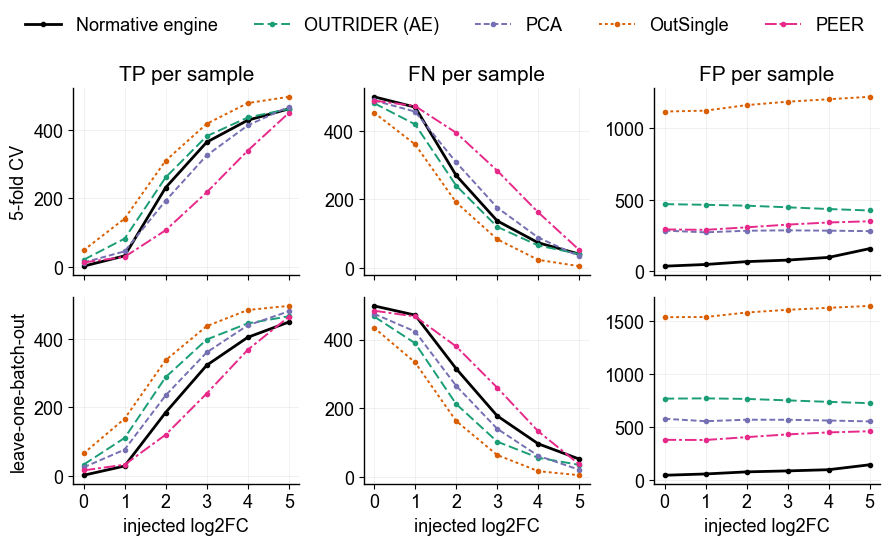

In [8]:
def confusion_panels(conf=CONF, splits=("cv", "lobo"), arms=ARMS, save=True):
    metrics = ["TP", "FN", "FP"]
    fig, axes = plt.subplots(len(splits), len(metrics), figsize=(3 * len(metrics), 2.5 * len(splits)),
                             sharex=True, squeeze=False)
    for i, split in enumerate(splits):
        for j, m in enumerate(metrics):
            ax = axes[i, j]
            for arm in arms:
                s = conf.loc[(split, arm), m]
                ax.plot(s.index, s.values, color=COLORS[arm], ls=STYLES[arm], marker="o", ms=3,
                        lw=2.0 if arm == "engine" else 1.4, label=LABELS[arm] if (i, j) == (0, 0) else None)
            if i == 0:
                ax.set_title(f"{m} per sample")
            if j == 0:
                ax.set_ylabel(SPLIT_TITLE[split])
            if i == len(splits) - 1:
                ax.set_xlabel("injected log2FC")
            ax.set_xticks(conf.index.get_level_values("log2fc").unique())
            ax.grid(alpha=0.25, lw=0.5)
    fig.legend(loc="upper center", ncol=len(arms), frameon=False, bbox_to_anchor=(0.5, 1.1))
    fig.tight_layout()
    if save:
        fig.savefig(FIGDIR / "persample_confusion.png", dpi=300, bbox_inches="tight")
    return fig


confusion_panels();